# Rol 2 — Síntesis del instrumento y función de fitness

Este notebook utiliza la representación del cromosoma y la melodía
extraída por el Rol 1 para generar un sonido de flauta sintetizada.

El instrumento se controla mediante ocho genes: amplitudes de tres
armónicos, ataque, decaimiento, sostenido, relajación y ruido de soplo.

Se comprobarán la síntesis, los silencios y las funciones de evaluación
mediante STFT en decibelios y croma.

Las primeras comparaciones utilizan audios sintéticos para verificar
el funcionamiento del código. La evaluación del parecido con una
flauta requiere una referencia instrumental independiente.


## 1. Configuración del entorno

Se localiza la raíz del proyecto y se importan las funciones compartidas.

Del Rol 1 se reutilizan la lectura del CSV, la representación del
cromosoma y la conversión a parámetros físicos. Del Rol 2 se importan
las funciones de síntesis, exportación y evaluación.

In [5]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Audio, display

RAIZ = Path.cwd().resolve()

if not (RAIZ / "src" / "representacion.py").is_file():
    RAIZ = RAIZ.parent

if not (RAIZ / "src" / "representacion.py").is_file():
    raise FileNotFoundError(
        "Ejecuta el notebook desde la raíz del proyecto "
        "o desde la carpeta notebooks/."
    )

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import src.representacion as rep

from src.extraccion import (
    cargar_melodia_csv,
    nombre_nota_midi,
)

from src.sintesis import (
    FRECUENCIA_MUESTREO,
    sintetizar_instrumento,
    guardar_wav,
)

from src.fitness import (
    evaluar_audio,
    evaluar_individuo,
)

print(f"Raíz del proyecto: {RAIZ}")
print(f"Frecuencia de muestreo: {FRECUENCIA_MUESTREO} Hz")
print(f"Genes definidos por el Rol 1: {rep.num_genes()}")

Raíz del proyecto: C:\Users\Asus\Downloads\Sistemas inteligentes\silbido-a-instrumento-prototipo-AG-IA
Frecuencia de muestreo: 22050 Hz
Genes definidos por el Rol 1: 8


## 2. Carga de la melodía extraída por el Rol 1

Se utiliza el archivo datos/procesados/melodia_01.csv, que contiene
una nota MIDI y una duración en segundos por evento.

El valor -1 representa un silencio. La melodía permanece fija:
el algoritmo genético modificará los parámetros del instrumento,
no las notas ni sus duraciones.

In [6]:
ruta_csv = RAIZ / "datos" / "procesados" / "melodia_01.csv"

notas, duraciones = cargar_melodia_csv(ruta_csv)

if notas.size == 0 or notas.size != duraciones.size:
    raise ValueError(
        "La melodía está vacía o no contiene una duración por evento."
    )

if not np.all(np.isfinite(duraciones)) or np.any(duraciones <= 0):
    raise ValueError("Las duraciones deben ser positivas y finitas.")

inicio_eventos = np.concatenate((
    [0.0],
    np.cumsum(duraciones)[:-1],
))

tabla_melodia = pd.DataFrame({
    "nota_midi": notas,
    "nombre": [nombre_nota_midi(int(n)) for n in notas],
    "inicio_s": inicio_eventos,
    "duracion_s": duraciones,
})

display(tabla_melodia)

print(f"Eventos: {len(notas)}")
print(f"Notas: {np.count_nonzero(notas != -1)}")
print(f"Silencios: {np.count_nonzero(notas == -1)}")
print(f"Duración total del CSV: {duraciones.sum():.3f} s")

,nota_midi,nombre,inicio_s,duracion_s
0,-1,Silencio (-1),0.000,0.128
1,93,La6 (93),0.128,0.244
2,96,Do7 (96),0.372,0.104
3,-1,Silencio (-1),0.476,0.139
4,92,Sol#6 (92),0.615,0.244
5,95,Si6 (95),0.859,0.255
6,92,Sol#6 (92),1.114,0.279
7,-1,Silencio (-1),1.393,0.035
8,95,Si6 (95),1.428,0.232
9,-1,Silencio (-1),1.660,0.035


Eventos: 16
Notas: 11
Silencios: 5
Duración total del CSV: 2.705 s


## 3. Cromosoma y parámetros del instrumento

Se obtiene el cromosoma inicial desde los valores por defecto del
Rol 1. Sus ocho genes están normalizados entre 0 y 1.

La función decodificar() transforma esos valores a amplitudes y
tiempos físicos. Los valores por defecto constituyen una configuración
inicial de prueba; no son parámetros optimizados ni una referencia real.

In [7]:
gen_prueba = rep.obtener_valores_default(normalizado=True)

valido, mensaje = rep.validar_individuo(gen_prueba)

if not valido:
    raise ValueError(mensaje)

parametros = rep.decodificar(gen_prueba)

tabla_genes = pd.DataFrame([
    {
        "indice": indice,
        "gen": especificacion.nombre,
        "valor_normalizado": gen_prueba[indice],
        "valor_fisico": parametros[especificacion.nombre],
        "unidad": especificacion.unidad,
    }
    for indice, especificacion in enumerate(rep.GENES_SCHEMA)
])

display(tabla_genes)

,indice,gen,valor_normalizado,valor_fisico,unidad
0,0,amp_arm1,0.888889,0.90,amplitud rel.
1,1,amp_arm2,0.312500,0.25,amplitud rel.
2,2,amp_arm3,0.160000,0.08,amplitud rel.
3,3,ataque_s,0.183673,0.05,segundos
4,4,decaimiento_s,0.254237,0.08,segundos
5,5,sostenido_rel,0.777778,0.80,amplitud rel.
6,6,relajacion_s,0.186441,0.06,segundos
7,7,ruido_soplo,0.160000,0.04,amplitud rel.


## 4. Síntesis de la melodía

Cada nota se genera sumando tres armónicos y ruido de soplo.
La envolvente ADSR controla la evolución de su amplitud.

Todas las etapas de la envolvente quedan dentro de la duración
del evento. Si no caben, sus tiempos se reducen proporcionalmente.

Se emplea una semilla fija para el ruido y una ganancia fija para
todos los individuos. Los silencios generan muestras de valor cero.

In [11]:
import importlib
import inspect
import src.sintesis as modulo_sintesis
import src.fitness as modulo_fitness

# Recargar el código guardado en disco.
importlib.invalidate_caches()
importlib.reload(modulo_sintesis)
importlib.reload(modulo_fitness)

# Actualizar también las funciones importadas en el notebook.
sintetizar_instrumento = modulo_sintesis.sintetizar_instrumento
guardar_wav = modulo_sintesis.guardar_wav
FRECUENCIA_MUESTREO = modulo_sintesis.FRECUENCIA_MUESTREO

evaluar_audio = modulo_fitness.evaluar_audio
evaluar_individuo = modulo_fitness.evaluar_individuo

print("Archivo cargado:", modulo_sintesis.__file__)
print("Firma:", inspect.signature(sintetizar_instrumento))
print("Genes recibidos:", len(gen_prueba))

assert "semilla" in inspect.signature(
    sintetizar_instrumento
).parameters, (
    "El archivo guardado sigue siendo la versión antigua. "
    "Reemplaza el contenido del archivo indicado arriba "
    "por la versión de ocho genes y guárdalo."
)

assert len(gen_prueba) == 8

print("Versión de ocho genes cargada correctamente.")

Archivo cargado: C:\Users\Asus\Downloads\Sistemas inteligentes\silbido-a-instrumento-prototipo-AG-IA\src\sintesis.py
Firma: (notas, duraciones, gen, *, semilla=2026)
Genes recibidos: 8
Versión de ocho genes cargada correctamente.


In [12]:
audio = sintetizar_instrumento(
    notas,
    duraciones,
    gen_prueba,
)

muestras_esperadas = int(round(
    duraciones.sum() * FRECUENCIA_MUESTREO
))

assert audio.ndim == 1
assert len(audio) == muestras_esperadas
assert np.all(np.isfinite(audio))
assert np.max(np.abs(audio)) <= 1.0

print(f"Muestras generadas: {len(audio)}")
print(f"Duración: {len(audio) / FRECUENCIA_MUESTREO:.6f} s")
print(f"Amplitud máxima: {np.max(np.abs(audio)):.4f}")

display(
    Audio(
        audio,
        rate=FRECUENCIA_MUESTREO,
        normalize=False,
    )
)

Muestras generadas: 59645
Duración: 2.704989 s
Amplitud máxima: 0.3626


## 5. Comprobación de reproducibilidad y silencios

Se verifica que la misma melodía y el mismo cromosoma produzcan
exactamente el mismo audio al utilizar la semilla predeterminada.

También se comprueba que los eventos identificados como silencios
contengan únicamente muestras cero.

In [13]:
audio_repetido = sintetizar_instrumento(
    notas,
    duraciones,
    gen_prueba,
)

assert np.array_equal(audio, audio_repetido), (
    "La síntesis no está produciendo resultados reproducibles."
)

fronteras = np.rint(
    np.concatenate(([0.0], np.cumsum(duraciones)))
    * FRECUENCIA_MUESTREO
).astype(int)

for indice, nota in enumerate(notas):
    if nota == -1:
        fragmento = audio[
            fronteras[indice]:fronteras[indice + 1]
        ]

        assert np.all(fragmento == 0.0), (
            f"El silencio del evento {indice} contiene sonido."
        )

print("Reproducibilidad: correcta.")
print("Silencios: correctos.")

Reproducibilidad: correcta.
Silencios: correctos.


## 6. Exportación del audio inicial

Se guarda la melodía sintetizada en formato WAV mono, a 22050 Hz
y PCM de 16 bits.

Este archivo corresponde al cromosoma por defecto. Todavía no es
el mejor individuo evolucionado ni una salida de la generación cero
de una población.

In [14]:
ruta_audio = guardar_wav(
    RAIZ / "resultados" / "audios" / "sintesis_melodia_rol1.wav",
    audio,
)

print(f"Audio guardado: {ruta_audio.relative_to(RAIZ)}")

Audio guardado: resultados\audios\sintesis_melodia_rol1.wav


## 7. Métricas de evaluación

### Métrica principal: STFT en decibelios

Se calcula el error absoluto medio entre las magnitudes de los
espectrogramas expresadas en dB, utilizando una referencia fija
de amplitud 1 y un piso de -80 dB.

El error se transforma en aptitud mediante:

fitness_stft = 1 / (1 + error_stft_db / 10)

El algoritmo genético maximiza esta aptitud. Una coincidencia exacta
obtiene 1. El factor 10 controla la escala de la transformación;
no representa un umbral validado de calidad perceptual.

### Métrica alternativa: croma

Se compara la distribución de energía en las doce clases de altura
mediante similitud coseno. La aptitud está entre 0 y 1.

El croma puede distinguir poco entre instrumentos que interpretan
las mismas notas, por lo que se analizará junto con la métrica STFT.

### Condiciones de comparación

Los audios deben ser mono, tener una frecuencia de muestreo de
22050 Hz, igual longitud y eventos temporalmente alineados.

No se utiliza MSE de la onda cruda porque diferencias pequeñas
de fase pueden producir errores grandes entre sonidos similares.

## 8. Comprobación de las métricas con un audio idéntico

Se compara el audio sintetizado consigo mismo.

El resultado esperado es error STFT igual a cero y ambas aptitudes
iguales a uno. Esta comprobación verifica la implementación;
no mide parecido con una flauta real.

In [15]:
resultado_identico = evaluar_audio(audio, audio)

assert np.isclose(resultado_identico["error_stft_db"], 0.0)
assert np.isclose(resultado_identico["fitness_stft"], 1.0)
assert np.isclose(resultado_identico["fitness_croma"], 1.0)

display(pd.DataFrame([resultado_identico]))

,error_stft_db,fitness_stft,fitness_croma
0,0.0,1.0,1.0


In [19]:
# Copiar el cromosoma inicial de ocho genes.
gen_distinto = gen_prueba.copy()

# Modificar únicamente la amplitud del segundo armónico.
indice = rep.obtener_nombres_genes().index("amp_arm2")
gen_distinto[indice] = 0.95

aptitud = evaluar_individuo(
    gen=gen_distinto,
    notas=notas,
    duraciones=duraciones,
    referencia=audio,  # Comprobación con referencia sintética.
    metrica="stft",
)

print(f"Aptitud que recibiría el AG: {aptitud:.4f}")

Aptitud que recibiría el AG: 0.9852


## 9. Comparación técnica al modificar un gen

Se copia el cromosoma inicial y se modifica únicamente la amplitud
del segundo armónico.

Las notas, duraciones y los demás genes permanecen constantes.
Ambos audios se comparan para comprobar que el fitness espectral
detecta el cambio introducido.

In [20]:
gen_distinto = gen_prueba.copy()

indice_armonico_2 = rep.obtener_nombres_genes().index("amp_arm2")
gen_distinto[indice_armonico_2] = 0.95

audio_distinto = sintetizar_instrumento(
    notas,
    duraciones,
    gen_distinto,
)

resultado_distinto = evaluar_audio(
    audio_distinto,
    audio,
)

assert resultado_distinto["error_stft_db"] > 0.0

tabla_comprobacion = pd.DataFrame([
    {
        "comparacion": "Audio consigo mismo",
        **resultado_identico,
    },
    {
        "comparacion": "Segundo armónico modificado",
        **resultado_distinto,
    },
])

display(tabla_comprobacion)

print("Audio con el segundo armónico modificado:")

display(
    Audio(
        audio_distinto,
        rate=FRECUENCIA_MUESTREO,
        normalize=False,
    )
)

,comparacion,error_stft_db,fitness_stft,fitness_croma
0,Audio consigo mismo,0.000000,1.000000,1.000000
1,Segundo armónico modificado,0.149971,0.985224,0.999958


Audio con el segundo armónico modificado:


## 10. Comprobación de la interfaz de evaluación de individuos

La función evaluar_individuo() recibe un cromosoma, la melodía,
una referencia y el nombre de la métrica. Sintetiza el individuo
y devuelve una aptitud numérica que el AG debe maximizar.

En esta comprobación se utiliza el audio inicial como referencia
sintética temporal. La evaluación instrumental deberá utilizar
posteriormente una grabación independiente de flauta.

In [21]:
aptitud = evaluar_individuo(
    gen=gen_distinto,
    notas=notas,
    duraciones=duraciones,
    referencia=audio,
    metrica="stft",
)

assert np.isclose(
    aptitud,
    resultado_distinto["fitness_stft"],
)

print(f"Aptitud devuelta al AG: {aptitud:.6f}")

Aptitud devuelta al AG: 0.985224


## 11. Estado de la integración y próximos experimentos

Las celdas anteriores conectan la representación de ocho genes y
la melodía del Rol 1 con la síntesis y las métricas del Rol 2.

Si las verificaciones pasan, se comprueban:

- La generación de audio con los ocho genes.
- La conservación de la duración definida por el CSV.
- Los silencios absolutos.
- La reproducibilidad de la síntesis.
- La evaluación de audios idénticos y de un cromosoma modificado.

Estas verificaciones no demuestran todavía semejanza instrumental.

## 12. Referencia instrumental de flauta

Se construye una referencia con grabaciones reales de flauta sin
vibrato de University of Iowa Musical Instrument Samples.

El montaje conserva las notas, duraciones y silencios del CSV.
Las muestras originales se conservan junto con sus fuentes.

Los comienzos de las notas se estiman automáticamente y deben
revisarse mediante escucha. La referencia es independiente del
sintetizador que evaluará el algoritmo genético.

In [22]:
import json
import re
from html import unescape
from math import gcd
from urllib.parse import urljoin, urlsplit, unquote, quote
from urllib.request import Request, urlopen

import soundfile as sf
from scipy.signal import resample_poly


PAGINA_FLAUTA = (
    "https://theremin.music.uiowa.edu/"
    "MIS-Pitches-2012/MISFlute2012.html"
)

ORIGINALES = (
    RAIZ / "datos" / "audio" / "referencias" / "originales"
)
ORIGINALES.mkdir(parents=True, exist_ok=True)

CARPETA_ROL2 = RAIZ / "resultados" / "rol2"
CARPETA_ROL2.mkdir(parents=True, exist_ok=True)

CLASES_NOTAS = [
    "C", "Db", "D", "Eb", "E", "F",
    "Gb", "G", "Ab", "A", "Bb", "B",
]


def descargar_bytes(url):
    url = quote(url, safe=":/%?=&")
    peticion = Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
    )
    with urlopen(peticion, timeout=60) as respuesta:
        return respuesta.read()


html_flauta = descargar_bytes(PAGINA_FLAUTA).decode(
    "utf-8", errors="replace"
)

enlaces = [
    urljoin(PAGINA_FLAUTA, unescape(href))
    for href in re.findall(
        r"""href\s*=\s*["']([^"']+)["']""",
        html_flauta,
        flags=re.IGNORECASE,
    )
]

# Si un comienzo automático resulta incorrecto, indica aquí
# el instante correcto en segundos de la muestra remuestreada.
# Formato: {numero_midi: inicio_en_segundos}
INICIOS_MANUALES = {}

muestras_reales = {}
registro_fuentes = []

for midi in sorted(set(int(n) for n in notas if n != -1)):
    nombre = f"{CLASES_NOTAS[midi % 12]}{midi // 12 - 1}"
    prefijo = f"Flute.nonvib.ff.{nombre}.stereo."

    candidatos = [
        url for url in enlaces
        if unquote(urlsplit(url).path).split("/")[-1].startswith(prefijo)
        and urlsplit(url).path.lower().endswith((".aif", ".aiff"))
    ]

    if not candidatos:
        raise ValueError(f"No se encontró muestra para MIDI {midi}.")

    url = candidatos[0]
    nombre_archivo = unquote(urlsplit(url).path).split("/")[-1]
    ruta_original = ORIGINALES / nombre_archivo

    if not ruta_original.exists():
        contenido = descargar_bytes(url)

        if contenido[:4] != b"FORM":
            raise ValueError(f"La descarga no es un archivo AIFF: {url}")

        ruta_original.write_bytes(contenido)

    muestra, sr_original = sf.read(
        ruta_original,
        dtype="float64",
        always_2d=True,
    )

    if muestra.size == 0 or not np.all(np.isfinite(muestra)):
        raise ValueError(f"Muestra inválida: {nombre_archivo}")

    muestra = muestra.mean(axis=1)

    if sr_original != FRECUENCIA_MUESTREO:
        divisor = gcd(sr_original, FRECUENCIA_MUESTREO)
        muestra = resample_poly(
            muestra,
            FRECUENCIA_MUESTREO // divisor,
            sr_original // divisor,
        )

    # Detectar región activa mediante energía en bloques.
    bloque = 256
    cantidad_bloques = len(muestra) // bloque

    if cantidad_bloques == 0:
        raise ValueError(f"Muestra demasiado corta: {nombre_archivo}")

    rms = np.sqrt(np.mean(
        muestra[:cantidad_bloques * bloque].reshape(
            cantidad_bloques, bloque
        ) ** 2,
        axis=1,
    ))

    if rms.max() <= 1e-8:
        raise ValueError(f"Muestra silenciosa: {nombre_archivo}")

    activos = np.flatnonzero(rms > rms.max() * 0.03)
    inicio = max(0, (int(activos[0]) - 1) * bloque)
    fin = min(len(muestra), (int(activos[-1]) + 1) * bloque)

    if midi in INICIOS_MANUALES:
        inicio_s = INICIOS_MANUALES[midi]

        if not np.isfinite(inicio_s) or inicio_s < 0:
            raise ValueError("Comienzo manual inválido.")

        inicio = int(round(inicio_s * FRECUENCIA_MUESTREO))

    if inicio >= fin:
        raise ValueError(f"Recorte inválido para MIDI {midi}.")

    muestras_reales[midi] = muestra[inicio:fin]

    registro_fuentes.append({
        "midi": midi,
        "archivo": nombre_archivo,
        "url": url,
        "sr_original": int(sr_original),
        "inicio_s": inicio / FRECUENCIA_MUESTREO,
        "duracion_disponible_s": (fin - inicio) / FRECUENCIA_MUESTREO,
    })

# Mismas fronteras temporales que utiliza la síntesis.
fronteras_ref = np.rint(
    np.concatenate(([0.0], np.cumsum(duraciones)))
    * FRECUENCIA_MUESTREO
).astype(int)

referencia = np.zeros(fronteras_ref[-1], dtype=float)

for i, nota in enumerate(notas):
    if nota == -1:
        continue

    inicio, fin = fronteras_ref[i:i + 2]
    cantidad = fin - inicio
    muestra = muestras_reales[int(nota)]

    if len(muestra) < cantidad:
        raise ValueError(
            f"La muestra MIDI {int(nota)} no alcanza para el evento {i}. "
            "Revisa el comienzo o utiliza una muestra más larga."
        )

    evento = muestra[:cantidad].copy()

    fade = min(
        round(0.005 * FRECUENCIA_MUESTREO),
        cantidad // 2,
    )

    if fade > 1:
        evento[:fade] *= np.linspace(0.0, 1.0, fade)
        evento[-fade:] *= np.linspace(1.0, 0.0, fade)

    referencia[inicio:fin] = evento

pico_referencia = np.max(np.abs(referencia))

if pico_referencia <= 1e-8:
    raise ValueError("La referencia resultante es silenciosa.")

# Una única ganancia para todo el montaje.
ganancia_referencia = 0.9 / pico_referencia
referencia *= ganancia_referencia

ruta_referencia = (
    RAIZ / "datos" / "audio" / "referencias"
    / "flauta_referencia_01.wav"
)

guardar_wav(ruta_referencia, referencia)

# Usar en las evaluaciones exactamente el audio guardado.
referencia, sr_ref = sf.read(
    ruta_referencia,
    dtype="float32",
)

metadatos = {
    "coleccion": "University of Iowa Musical Instrument Samples",
    "pagina": PAGINA_FLAUTA,
    "condiciones": "https://theremin.music.uiowa.edu/MIS.html",
    "tecnica": "Sin vibrato; dinámica ff",
    "ganancia_global": float(ganancia_referencia),
    "fade_bordes_s": 0.005,
    "notas": notas.astype(int).tolist(),
    "duraciones_s": duraciones.tolist(),
    "muestras": registro_fuentes,
}

ruta_referencia.with_suffix(".json").write_text(
    json.dumps(metadatos, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

display(pd.DataFrame(registro_fuentes))

print("Referencia preparada. Revisa sus comienzos al escuchar:")
display(Audio(
    referencia,
    rate=sr_ref,
    normalize=False,
))

,midi,archivo,url,sr_original,inicio_s,duracion_disponible_s
0,88,Flute.nonvib.ff.E6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.03483,2.043356
1,89,Flute.nonvib.ff.F6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.03483,1.671837
2,91,Flute.nonvib.ff.G6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.03483,1.915646
3,92,Flute.nonvib.ff.Ab6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.02322,1.996916
4,93,Flute.nonvib.ff.A6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.03483,2.054966
5,95,Flute.nonvib.ff.B6.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.08127,2.240726
6,96,Flute.nonvib.ff.C7.stereo.aif,https://theremin.music.uiowa.edu/sound files/M...,44100,0.02322,2.008526


Referencia preparada. Revisa sus comienzos al escuchar:


## 13. Comparación de STFT y croma

Se evalúan el cromosoma por defecto y cinco cromosomas aleatorios
sobre la misma melodía y referencia.

Se comparan sus puntuaciones y posiciones en cada métrica.
Estos candidatos no constituyen una población evolucionada por el AG.

In [23]:
rng_comparacion = np.random.default_rng(42)

candidatos = {"default": gen_prueba.copy()}

for i in range(5):
    candidatos[f"aleatorio_{i + 1}"] = (
        rep.generar_individuo_aleatorio(rng=rng_comparacion)
    )

filas = []

for nombre, cromosoma in candidatos.items():
    senal = sintetizar_instrumento(
        notas, duraciones, cromosoma
    )

    assert len(senal) == len(referencia)

    filas.append({
        "candidato": nombre,
        **evaluar_audio(senal, referencia),
        **{
            f"gen_{nombre_gen}": float(valor)
            for nombre_gen, valor in zip(
                rep.obtener_nombres_genes(), cromosoma
            )
        },
    })

comparacion = pd.DataFrame(filas)

for metrica in ["stft", "croma"]:
    comparacion[f"puesto_{metrica}"] = comparacion[
        f"fitness_{metrica}"
    ].rank(ascending=False, method="min")

comparacion.to_csv(
    CARPETA_ROL2 / "comparacion_metricas.csv",
    index=False,
)

display(comparacion[[
    "candidato",
    "error_stft_db",
    "fitness_stft",
    "fitness_croma",
    "puesto_stft",
    "puesto_croma",
]])

,candidato,error_stft_db,fitness_stft,fitness_croma,puesto_stft,puesto_croma
0,default,4.714410,0.679606,0.914508,1.0,2.0
1,aleatorio_1,9.417012,0.515012,0.906468,5.0,3.0
2,aleatorio_2,5.495775,0.645337,0.920207,2.0,1.0
3,aleatorio_3,9.062671,0.524585,0.855770,4.0,6.0
4,aleatorio_4,9.984811,0.500380,0.870044,6.0,5.0
5,aleatorio_5,8.288302,0.546798,0.893893,3.0,4.0


## 14. Fitness al variar un gen

Se modifica amp_arm2 en 41 valores normalizados entre 0 y 1.
Los demás genes, la melodía y la semilla de ruido permanecen fijos.

Este experimento muestra un corte unidimensional de la superficie
de fitness de ocho dimensiones.

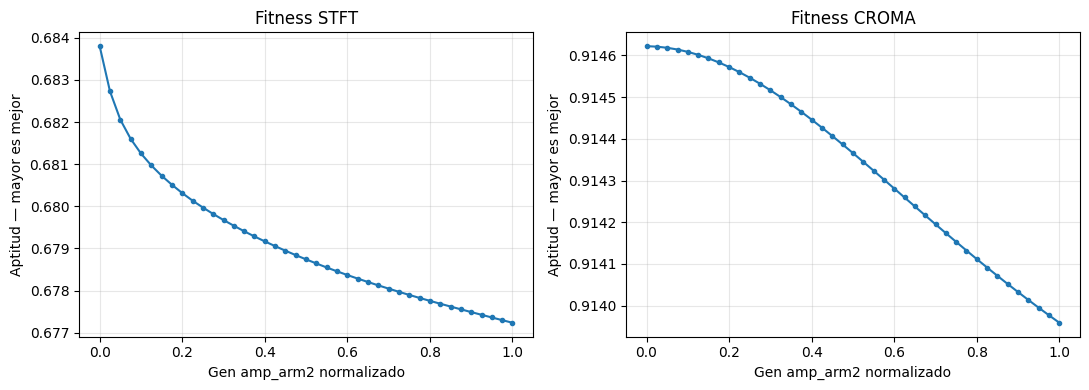

In [24]:
import matplotlib.pyplot as plt

indice_gen = rep.obtener_nombres_genes().index("amp_arm2")
filas_barrido = []

for valor in np.linspace(0.0, 1.0, 41):
    cromosoma = gen_prueba.copy()
    cromosoma[indice_gen] = valor

    senal = sintetizar_instrumento(
        notas, duraciones, cromosoma
    )

    filas_barrido.append({
        "gen_normalizado": float(valor),
        "amplitud_fisica": rep.decodificar(cromosoma)["amp_arm2"],
        **evaluar_audio(senal, referencia),
    })

barrido = pd.DataFrame(filas_barrido)

barrido.to_csv(
    CARPETA_ROL2 / "superficie_amp_arm2.csv",
    index=False,
)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

for eje, metrica in zip(ejes, ["stft", "croma"]):
    eje.plot(
        barrido["gen_normalizado"],
        barrido[f"fitness_{metrica}"],
        marker=".",
    )
    eje.set(
        title=f"Fitness {metrica.upper()}",
        xlabel="Gen amp_arm2 normalizado",
        ylabel="Aptitud — mayor es mejor",
    )
    eje.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    CARPETA_ROL2 / "superficie_amp_arm2.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 15. Exportación y comparación auditiva

Se guardan la referencia, la síntesis por defecto y el candidato
con mayor fitness STFT entre los seis evaluados.

El candidato seleccionado no es un resultado evolucionado por el AG.
Las reproducciones mantienen sus niveles de amplitud.

In [25]:
nombre_mejor = comparacion.loc[
    comparacion["fitness_stft"].idxmax(),
    "candidato",
]

audio_default = sintetizar_instrumento(
    notas, duraciones, gen_prueba
)

audio_mejor = sintetizar_instrumento(
    notas, duraciones, candidatos[nombre_mejor]
)

for nombre, senal in {
    "referencia_flauta": referencia,
    "sintesis_default": audio_default,
    "mejor_candidato_evaluado": audio_mejor,
}.items():
    guardar_wav(CARPETA_ROL2 / f"{nombre}.wav", senal)

    print(nombre)
    display(Audio(
        senal,
        rate=FRECUENCIA_MUESTREO,
        normalize=False,
    ))

np.save(
    CARPETA_ROL2 / "gen_mejor_candidato_evaluado.npy",
    candidatos[nombre_mejor],
)

print(f"Mejor candidato según STFT: {nombre_mejor}")

referencia_flauta


sintesis_default


mejor_candidato_evaluado


Mejor candidato según STFT: default


## 16. Superficie de fitness y elección de métrica

Una superficie de fitness asigna una aptitud a cada cromosoma.
En este proyecto relaciona los ocho parámetros del instrumento
con su similitud respecto a la referencia de flauta.

El gráfico obtenido muestra un corte de esa superficie: cambia
únicamente la amplitud del segundo armónico.

Una superficie relativamente suave favorece que pequeñas variaciones
de los genes produzcan cambios graduales de aptitud. Esto ayuda
a conservar mejoras y explorar soluciones cercanas. Sin embargo,
un AG no requiere derivadas ni garantiza encontrar un óptimo global.

La semilla fija del ruido permite atribuir los cambios de fitness
al gen modificado, en lugar de a nuevas realizaciones aleatorias.

Se mantiene STFT como métrica principal inicial porque compara
la distribución espectral y su evolución temporal. El croma aporta
una comparación de clases de altura y puede distinguir poco entre
timbres que interpretan la misma melodía.

La recomendación debe contrastarse con los resultados de la tabla,
las curvas y la escucha. Una puntuación mayor de una métrica respecto
a otra no demuestra que esa métrica sea superior, pues sus escalas
son diferentes.

### Limitaciones

- Los comienzos automáticos de las muestras requieren revisión.
- La referencia utiliza una sola dinámica instrumental, ff.
- Los recortes y su suavizado modifican la articulación original.
- La comparación depende de la ganancia y la alineación temporal.
- El sintetizador utiliza tres armónicos y ruido simplificado.
- Los candidatos evaluados no sustituyen los experimentos del AG.